# Residual diagnostic

Dependence in the errors of the 90-day and the seasonal EMOS on the validation fold, measured on the normal scores of the PIT. B/A is estimated on the train fold. Maintenance outages are not filtered, which can inflate the dependence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows, evaluation_rows, history_rows
from windai.models.EMOS import EMOS, SeasonalEMOS, RollingEMOS, ensemble_stats, score_contributions
from windai.evaluation import dependence as dep

pd.set_option("display.width", 200)
df, curve = load_dataset("train", fit="val")
train, history, val = training_rows(df, "val"), history_rows(df, "val"), evaluation_rows(df, "val")
y = val["power"].to_numpy()
obs = ~np.isnan(y)
rows = val.loc[obs].reset_index(drop=True)
hidden = val.drop(columns=["power", "cf"])

fc = {"rolling_90": RollingEMOS(90).fit(history).predict(hidden),
      "seasonal": SeasonalEMOS().fit(train).predict(hidden)}
z = {name: dep.normal_scores(f.pit_fn(y[obs], rng=0)) for name, f in fc.items()}
Z = {name: dep.z_matrix(rows, zz) for name, zz in z.items()}
zones = sorted(Z["rolling_90"])
models = list(Z)
print({name: {zone: m.shape for zone, m in Z[name].items()} for name in models})

{'rolling_90': {'ELSPOT NO1': (355, 24), 'ELSPOT NO2': (355, 24), 'ELSPOT NO3': (355, 24), 'ELSPOT NO4': (355, 24)}, 'seasonal': {'ELSPOT NO1': (355, 24), 'ELSPOT NO2': (355, 24), 'ELSPOT NO3': (355, 24), 'ELSPOT NO4': (355, 24)}}


## PIT

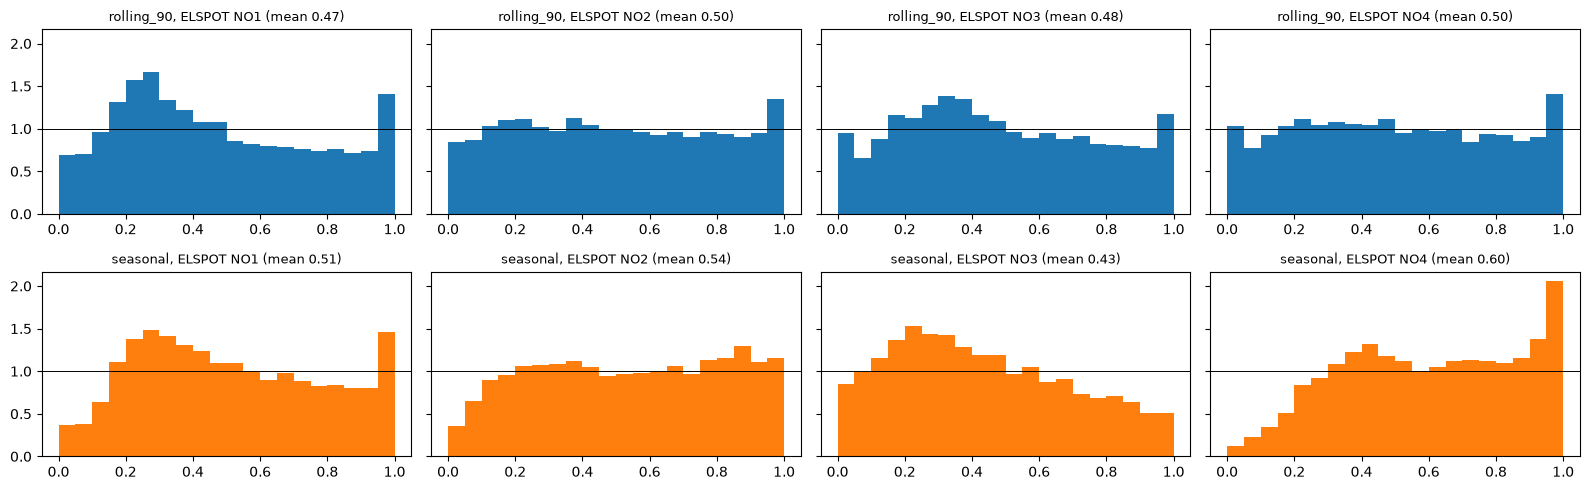

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(16, 5), sharey=True)
for i, name in enumerate(models):
    pit = fc[name].pit_fn(y[obs], rng=0)
    for j, zone in enumerate(zones):
        p = pit[rows["zone"].to_numpy() == zone]
        axes[i, j].hist(p, bins=20, range=(0, 1), density=True, color="C0" if i == 0 else "C1")
        axes[i, j].axhline(1, color="k", lw=0.7)
        axes[i, j].set_title(f"{name}, {zone} (mean {p.mean():.2f})", fontsize=9)
plt.tight_layout(); plt.show()

The 90-day model is close to flat in NO2–NO4, and the seasonal model shows the known bias in NO3 and NO4. NO1 is skewed for both models, so its dependence figures partly reflect the wrong distribution shape.

## Dependence within the forecast day

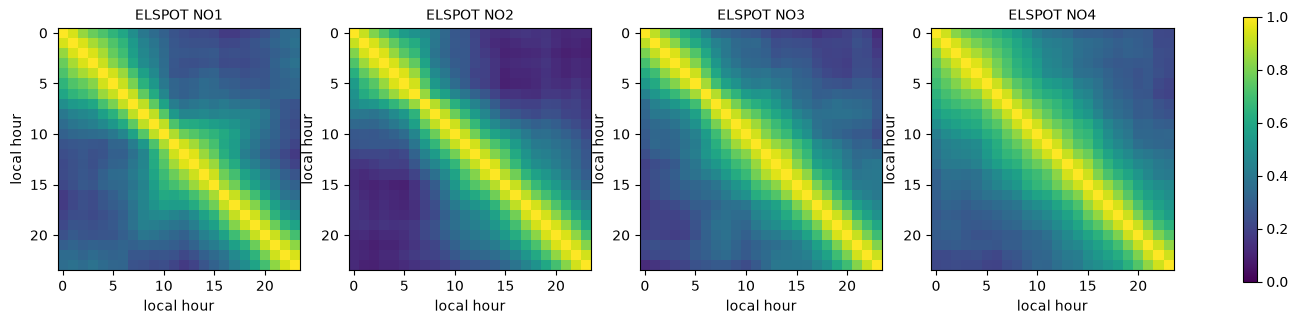

,ELSPOT NO1,ELSPOT NO2,ELSPOT NO3,ELSPOT NO4
hour lag 1,0.92,0.92,0.92,0.93
hour lag 3,0.69,0.68,0.69,0.75
hour lag 6,0.45,0.42,0.46,0.57
hour lag 12,0.29,0.19,0.30,0.34
hour lag 23,0.36,0.12,0.12,0.22


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
within = {}
for ax, zone in zip(axes, zones):
    C = Z["rolling_90"][zone].corr()
    within[zone] = C
    im = ax.imshow(C.to_numpy(), vmin=0, vmax=1, cmap="viridis")
    ax.set_title(zone, fontsize=10); ax.set_xlabel("local hour"); ax.set_ylabel("local hour")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

def mean_offdiag(C, k):
    return np.nanmean(np.diag(C.to_numpy(), k))
pd.DataFrame({zone: {f"hour lag {k}": mean_offdiag(C, k) for k in (1, 3, 6, 12, 23)} for zone, C in within.items()}).round(2)

The errors of neighbouring hours correlate at 0.92, falling to 0.42–0.57 at six hours and 0.19–0.34 at twelve. A forecast day's error is a few weather-error events rather than 24 independent errors.

## Dependence across issue days

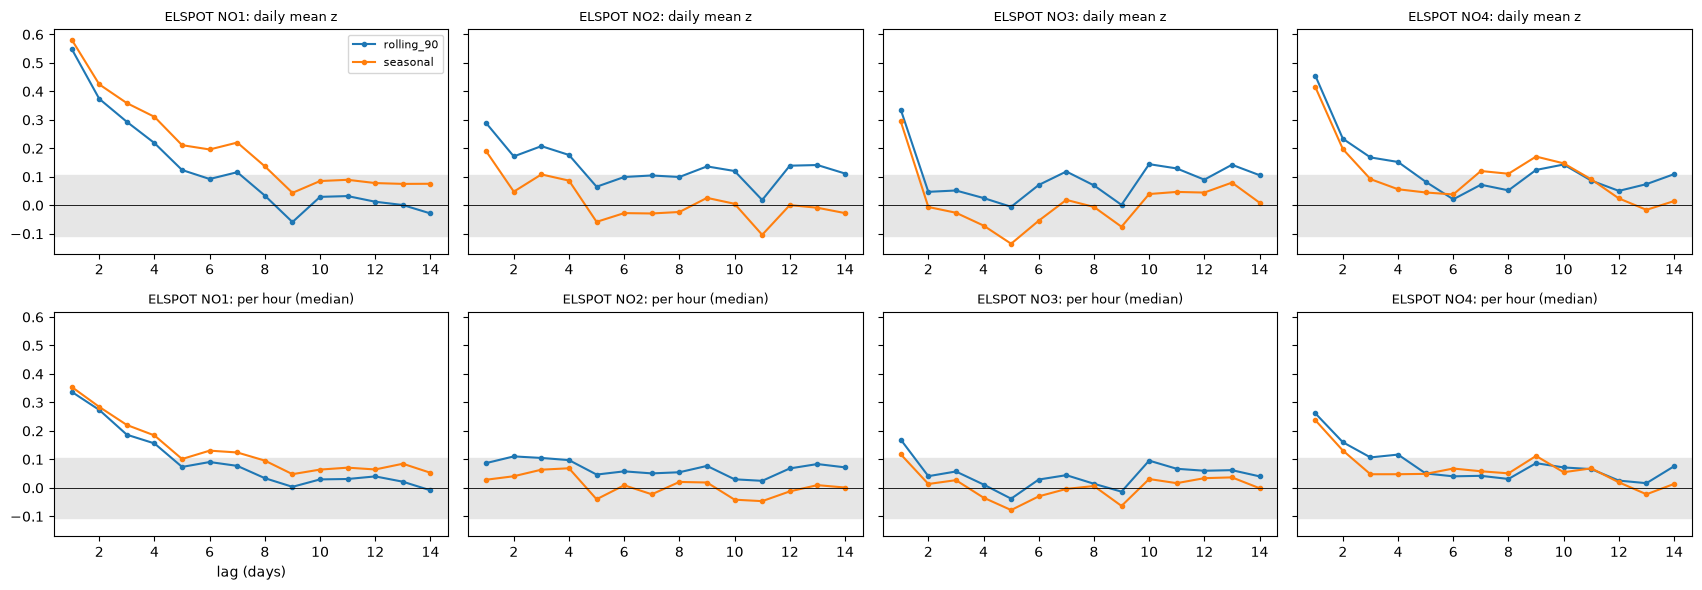

lag 1  lag 2  lag 7  lag 14
rolling_90 ELSPOT NO1   0.55   0.37   0.12   -0.03
           ELSPOT NO2   0.29   0.17   0.10    0.11
           ELSPOT NO3   0.34   0.05   0.12    0.11
           ELSPOT NO4   0.46   0.23   0.07    0.11
seasonal   ELSPOT NO1   0.58   0.42   0.22    0.08
           ELSPOT NO2   0.19   0.05  -0.03   -0.03
           ELSPOT NO3   0.29  -0.01   0.02    0.01
           ELSPOT NO4   0.42   0.20   0.12    0.01

In [4]:
acf_daily, acf_hourly = {}, {}
for name in models:
    for zone in zones:
        M = Z[name][zone]
        acf_daily[(name, zone)] = dep.acf(M.mean(axis=1))
        acf_hourly[(name, zone)] = np.nanmedian([dep.acf(M[h]) for h in range(24)], axis=0)

lags = np.arange(1, dep.MAX_LAG + 1)
fig, axes = plt.subplots(2, 4, figsize=(17, 6), sharey=True)
for j, zone in enumerate(zones):
    n = len(Z["rolling_90"][zone])
    for i, (table, label) in enumerate([(acf_daily, "daily mean z"), (acf_hourly, "per hour (median)")]):
        ax = axes[i, j]
        ax.axhspan(-2 / np.sqrt(n), 2 / np.sqrt(n), color="0.9")
        for name in models:
            ax.plot(lags, table[(name, zone)], marker="o", ms=3, label=name)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_title(f"{zone}: {label}", fontsize=9)
axes[1, 0].set_xlabel("lag (days)"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame({k: v[[0, 1, 6, 13]] for k, v in acf_daily.items()}, index=["lag 1", "lag 2", "lag 7", "lag 14"]).T.round(2)

The lag-1 autocorrelation is 0.3–0.55 for the daily mean and 0.1–0.35 per hour, and it fades within 2–4 days (5–8 in NO1). Both models agree at short lags, so that part comes from the weather errors. At long lags the 90-day model keeps a small positive correlation in NO2 and NO3, probably because consecutive issues share almost the same training window, while the seasonal model carries NO4's drift.

## Dependence between zones

In [5]:
for name in models:
    dm = pd.DataFrame({zone: Z[name][zone].mean(axis=1) for zone in zones})
    same_hour = pd.DataFrame({zone: Z[name][zone].stack() for zone in zones})
    print(f"{name}: correlation of the daily mean z\n{dm.corr().round(2)}\n")
    print(f"{name}: correlation of z at the same hour\n{same_hour.corr().round(2)}\n")

rolling_90: correlation of the daily mean z
            ELSPOT NO1  ELSPOT NO2  ELSPOT NO3  ELSPOT NO4
ELSPOT NO1        1.00        0.21        0.19       -0.03
ELSPOT NO2        0.21        1.00        0.13        0.10
ELSPOT NO3        0.19        0.13        1.00        0.15
ELSPOT NO4       -0.03        0.10        0.15        1.00

rolling_90: correlation of z at the same hour
            ELSPOT NO1  ELSPOT NO2  ELSPOT NO3  ELSPOT NO4
ELSPOT NO1        1.00        0.14        0.13       -0.01
ELSPOT NO2        0.14        1.00        0.06        0.05
ELSPOT NO3        0.13        0.06        1.00        0.08
ELSPOT NO4       -0.01        0.05        0.08        1.00

seasonal: correlation of the daily mean z
            ELSPOT NO1  ELSPOT NO2  ELSPOT NO3  ELSPOT NO4
ELSPOT NO1        1.00        0.10        0.17       -0.01
ELSPOT NO2        0.10        1.00        0.04        0.04
ELSPOT NO3        0.17        0.04        1.00        0.08
ELSPOT NO4       -0.01        0.04      

The correlations between zones are weak (at most 0.21) and close to zero between NO1 and NO4.

## Effective sample size

In [6]:
rows_neff = []
for name in models:
    for zone in zones:
        M = Z[name][zone]
        n = M.notna().any(axis=1).sum()
        per_hour = np.nanmedian([dep.n_eff(dep.acf(M[h]), M[h].notna().sum()) for h in range(24)])
        rows_neff.append({"model": name, "zone": zone, "n days": n,
                          "n_eff daily mean": dep.n_eff(acf_daily[(name, zone)], n),
                          "n_eff per hour (median)": per_hour})
neff = pd.DataFrame(rows_neff).set_index(["zone", "model"]).sort_index()
neff["n / n_eff (per hour)"] = neff["n days"] / neff["n_eff per hour (median)"]
neff.round(1)

n days  n_eff daily mean  n_eff per hour (median)  n / n_eff (per hour)
zone       model                                                                              
ELSPOT NO1 rolling_90     355              77.1                    101.4                   3.5
           seasonal       355              52.4                     74.8                   4.7
ELSPOT NO2 rolling_90     355              74.6                    153.1                   2.3
           seasonal       355             190.3                    272.5                   1.3
ELSPOT NO3 rolling_90     355             184.8                    245.7                   1.4
           seasonal       355             223.3                    277.8                   1.3
ELSPOT NO4 rolling_90     355              76.3                    126.3                   2.8
           seasonal       355              88.4                    121.8                   2.9

Per hour, n/n_eff is 1.3–2.3 in NO2 and NO3, about 2.8 in NO4 and 3.5–4.7 in NO1. The validation year is therefore worth roughly 75–280 independent days, depending on the zone.

## B/A

Static EMOS on the train fold, per zone and UTC hour: the ratio of the sandwich variance A⁻¹BA⁻¹ to the inverse Fisher information A⁻¹, with B assuming independence (lag 0) and with Newey–West at 7 and 14 lags.

In [7]:
static = EMOS().fit(train)
d = train.dropna(subset=["cf"])
m_all, s2_all = ensemble_stats(d)
y_all = np.clip(d["cf"].to_numpy(), 0, 1)
records = []
for (zone, hour), idx in d.groupby(["zone", "target_hour_utc"]).indices.items():
    theta = static.params.loc[(zone, hour), ["a", "b", "c", "d"]].to_numpy(dtype=float)
    yy, mm, ss = y_all[idx], m_all[idx], s2_all[idx]
    S = score_contributions(theta, yy, mm, ss)
    A = dep.numerical_hessian(lambda t: -score_contributions(t, yy, mm, ss).mean(axis=0), theta)
    dates = d["issue_date"].to_numpy()[idx]
    for lag in (0, 7, 14):
        ratio, top = dep.sandwich_ratios(A, dep.long_run_cov(S, lag, dates=dates))
        records.append({"zone": zone, "hour": hour, "lag": lag, **dict(zip(["a", "b", "c", "d"], ratio)),
                        "max eig A^-1 B": top})
ba = pd.DataFrame(records)
summary_ba = ba.groupby(["zone", "lag"])[["a", "b", "c", "d", "max eig A^-1 B"]].median()
summary_ba.round(2)

a     b     c     d  max eig A^-1 B
zone       lag                                        
ELSPOT NO1 0    0.86  1.17  2.17  1.57            2.46
           7    1.52  1.95  3.11  1.88            4.96
           14   1.88  2.60  3.67  2.17            7.44
ELSPOT NO2 0    0.85  0.82  2.77  1.66            3.21
           7    1.52  1.19  3.10  1.85            3.88
           14   1.98  1.37  3.14  1.91            4.20
ELSPOT NO3 0    0.76  1.13  3.26  2.07            3.81
           7    1.30  1.76  3.86  2.11            4.64
           14   1.75  2.13  4.21  2.19            5.10
ELSPOT NO4 0    0.71  1.29  1.72  1.26            1.99
           7    1.18  3.01  2.65  1.54            5.05
           14   1.41  4.14  3.04  1.55            7.27

In [8]:
# Serial dependence alone: the NW ratio relative to the independence (lag-0) ratio, median over hours
wide = ba.set_index(["zone", "hour", "lag"])[["a", "b", "c", "d"]].unstack("lag")
dep_only = pd.concat({f"B{L}/B0": wide.xs(L, axis=1, level="lag") / wide.xs(0, axis=1, level="lag") for L in (7, 14)}, axis=1)
dep_only.groupby(level="zone").median().round(2)

B7/B0                   B14/B0                  
               a     b     c     d      a     b     c     d
zone                                                       
ELSPOT NO1  1.71  1.66  1.43  1.24   2.18  2.14  1.70  1.39
ELSPOT NO2  1.72  1.45  1.11  1.10   2.19  1.65  1.12  1.16
ELSPOT NO3  1.67  1.52  1.24  1.11   2.26  1.78  1.41  1.17
ELSPOT NO4  1.68  2.34  1.50  1.15   2.00  3.22  1.68  1.15

Under independence, the location parameters behave as the model says (ratios 0.7–1.3), but the scale parameters don't (1.7–3.3 for c), which points to a misspecified shape (heavier tails, skew). Serial dependence multiplies the variance of the intercept by 1.7–2.2 and of the slope by 1.5–3.2. Location intervals that assume independent errors would be about 1.3–1.5 times too narrow. The ratios still grow at 14 lags, so these are rough figures.